# FMI radar reflectivity composite
This notebook describes how to access and use the FMI radar reflectivity composite dataset. The dataset includes radar reflectivity composite product over Finland, which is derived from the Finnish Meteorological Institute (FMI) radar network.

The dataset covers 2008-03-18 to 2026-11-01. In addition to the radar reflectivity composite product, the dataset includes information about which radar stations contributed to the composite at each time step.

The dataset is released under the CC BY 4.0 license.

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import xarray as xr

import mlcast_datasets

mlcast_datasets.__version__

In [ ]:
# open the mlcast datasets intake catalog
cat = mlcast_datasets.open_catalog()
list(cat.precipitation)

# 5-minute radar reflectivity

In [ ]:
ds = cat.precipitation.fi_fmi_dbz_5min.to_dask()
ds

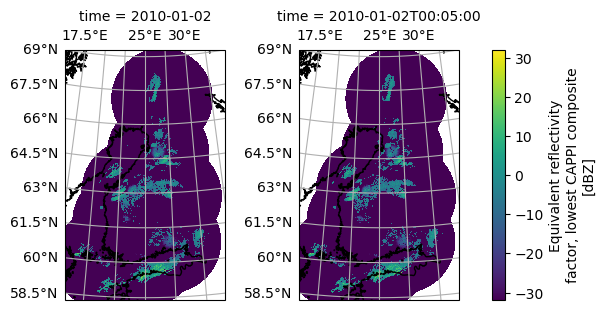

In [6]:
var_name = "dbz"

crs_name = ds[var_name].grid_mapping
data_crs = ccrs.Projection(ds[crs_name].crs_wkt)

g = (
    ds[var_name]
    .sel(time="2010-01-02")
    .isel(time=slice(None, 2))
    .plot(
        transform=data_crs,
        cmap="viridis",
        add_colorbar=True,
        col="time",
        robust=True,
        subplot_kws=dict(projection=data_crs),
    )
)

for ax in g.axs.flat:
    ax.coastlines()
    ax.gridlines(draw_labels=["top", "left"])

# Contributing radar stations

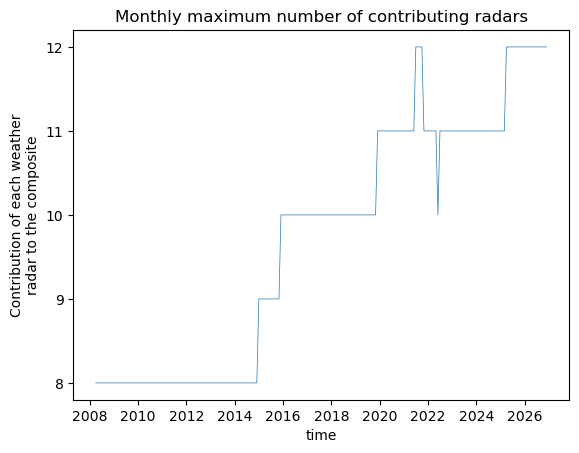

In [ ]:
# number of contributing radars per month
num_stations = (ds.radar_status == 1).sum("radar").resample(time="ME").max("time")

num_stations.plot.line(x="time", lw=0.5)
plt.title("Monthly maximum number of contributing radars")
plt.gca().yaxis.set_major_locator(plt.MultipleLocator(1))